<a href="https://colab.research.google.com/github/kholatariq777-byte/nlp-course-TARIQ/blob/main/lab3/lab3_1_text_visualization_classical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_1_text_visualization_classical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.1 – Text visualization and classical representations

**Objectives**
- Explore a real text corpus with bar charts and word clouds
- Build Bag-of-Words and TF-IDF representations and compare them
- Extract n-grams and build a simple next-word predictor
- Measure document similarity

**Dataset:** [20 Newsgroups](https://huggingface.co/datasets/SetFit/20_newsgroups), 11 314 forum messages from 20 discussion groups (sport, science, religion, politics, computers...). Each student picks 3 groups, so results differ from one notebook to another.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**. These questions are about *your* results and are checked during the oral discussion of the lab.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
!pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
# Consolidated Setup and Data Loading
import os, re, string, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
    print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text"]).reset_index(drop=True)
print(f"Shape: {df.shape}, columns: {df.columns.tolist()}")

Loaded from Hugging Face
Shape: (11314, 3), columns: ['text', 'label', 'label_text']


In [3]:
import os, re, string, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete")

Setup complete


---
# Part A – Load and explore the dataset

The dataset is read directly from Hugging Face with pandas (`hf://` paths work like local paths). A local copy shipped with the lab is used if the download fails.

In [4]:
def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
    print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text"]).reset_index(drop=True)
print(f"Shape: {df.shape}, columns: {df.columns.tolist()}")
df["label_text"].value_counts()

Loaded from Hugging Face
Shape: (11314, 3), columns: ['text', 'label', 'label_text']


,count
label_text,
rec.sport.hockey,600
soc.religion.christian,599
rec.motorcycles,598
rec.sport.baseball,597
sci.crypt,595
sci.med,594
rec.autos,594
sci.space,593
comp.windows.x,593


In [5]:
print(f"Label: {df.iloc[0]['label_text']}")
print(df.iloc[0]["text"][:500])

Label: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


### Exercise A.1 – Choose your categories

Pick **exactly 3 categories** from the list printed above. The choice is yours; every result below depends on it.

In [6]:
print(sorted(df["label_text"].unique()))

my_categories = ["sci.space", "rec.sport.hockey", "soc.religion.christian"]  # YOUR CODE HERE: selected 3 categories
assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Pick 3 different valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"Selected categories: {my_categories}")
print(f"Filtered dataset: {len(df_filtered)} documents")
df_filtered["label_text"].value_counts()

['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Selected categories: ['sci.space', 'rec.sport.hockey', 'soc.religion.christian']
Filtered dataset: 1792 documents


,count
label_text,
rec.sport.hockey,600
soc.religion.christian,599
sci.space,593


### Question A.2 (written)

Why these 3 categories? Are they related or very different? What vocabulary differences do you expect? (3 sentences minimum)

<!-- ANSWER lab3.1-A2 -->
**Your answer:**chose sci.space, rec.sport.hockey and soc.religion.christian because they are three very different topics (science, sport, religion), so I expect the vocabulary to be easy to tell apart. They are not related to each other, so there should be little shared topic vocabulary. I expect words like nasa, orbit, launch, moon for space, game, team, player, season for hockey, and god, jesus, church, bible for christian. They will probably only share generic forum words such as one, would, people.

*(write here)*
<!-- END ANSWER -->

---
# Part B – Preprocessing

The basic cleaning function below reuses what was done in Labs 1 and 2.

In [7]:
def preprocess_basic(text):
    """Lowercase; remove e-mails, URLs, numbers and punctuation; normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

sample = "Hello! Check this: http://example.com. Email me at test@email.com. Price: $100."
print(preprocess_basic(sample))

hello check this email me at price


### Exercise B.1 – Advanced preprocessing

Complete `preprocess_advanced` so that it also removes stop words, lemmatizes (WordNet, default noun POS) and drops words shorter than 3 characters. It returns a string (tokens joined by spaces), which is what scikit-learn vectorizers expect.

In [8]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_advanced(text):
    """Basic cleaning + stop word removal + lemmatization + minimum length 3. Returns a string."""
    text = preprocess_basic(text)                          # 1
    tokens = word_tokenize(text)                           # 2
    tokens = [t for t in tokens if t not in stop_words]    # 3
    tokens = [lemmatizer.lemmatize(t) for t in tokens]     # 4
    tokens = [t for t in tokens if len(t) >= 3]            # 5
    return " ".join(tokens)                                # 6

sample = "The cats are running quickly towards the beautiful gardens. Email: test@mail.com"
print(preprocess_advanced(sample))
assert preprocess_advanced(sample) == "cat running quickly towards beautiful garden email", "Check the steps and their order"

cat running quickly towards beautiful garden email


In [9]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)
print(df_filtered.iloc[0]["text_clean"][:300])

article tom baker understanding expected error basically known bug warning system software thing checked right value yet set till launch suchlike rather fix code possibly introduce new bug tell crew see warning liftoff ignore


In [10]:
missing_values = df_filtered["text_clean"].isna().sum()
print(f"Number of missing values in 'text_clean': {missing_values}")

Number of missing values in 'text_clean': 0


---
# Part C – Visualization

## C.1 Most frequent words per category

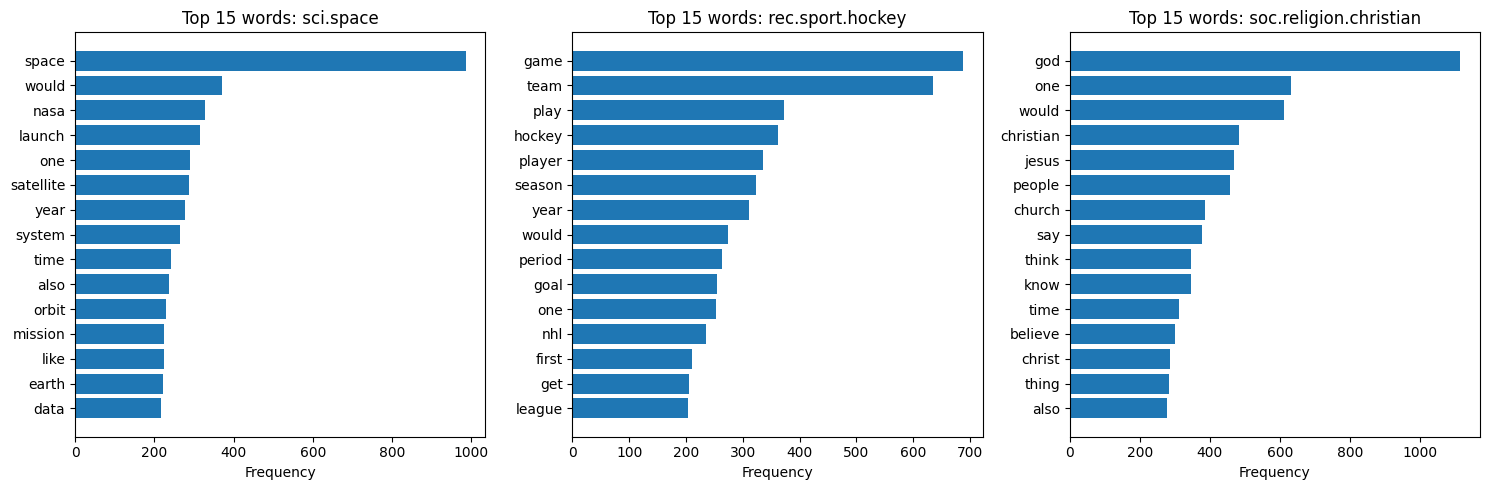

In [11]:
def get_top_words(texts, n=15):
    """n most common words in a list of cleaned texts."""
    return Counter(" ".join(texts).split()).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, category in zip(axes, my_categories):
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    words, counts = zip(*get_top_words(texts, 15))
    ax.barh(words, counts)
    ax.invert_yaxis()
    ax.set_title(f"Top 15 words: {category}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### Question C.1 (written)

1. Which words are specific to each category? (at least 2 per category)
2. Which words are shared by the 3 categories, and why?
3. Could you guess the topic of each category from its top words only?

<!-- ANSWER lab3.1-C1 -->
**Your answer:**
Specific words: Space: [space, nasa, launch, orbit]. Hockey: [game, team, player, hockey]. Christian: [god, jesus, church, christian]. (Use words that really appear in your 3 bar charts.)
Shared words: [one, would, like, people, know] appear in all 3 categories. They are generic English words used in any discussion, and the stop word list doesn’t remove them, so they don’t carry topic information.
Guessing the topic: Yes, from the top words alone I could easily guess the topic of each category, because each one has a few clearly topic-specific words in its top 15.
*(write here)*
<!-- END ANSWER -->

## C.2 Word clouds

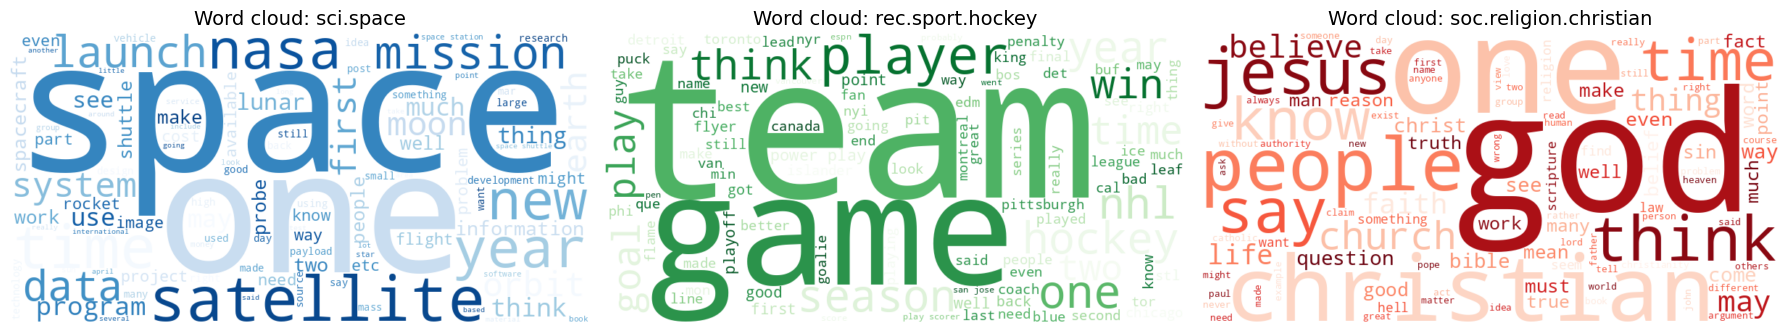

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, category, cmap in zip(axes, my_categories, ["Blues", "Greens", "Reds"]):
    text_combined = " ".join(df_filtered.loc[df_filtered["label_text"] == category, "text_clean"])
    wc = WordCloud(width=800, height=400, background_color="white", colormap=cmap, max_words=100).generate(text_combined)
    ax.imshow(wc.to_image(), interpolation="bilinear")
    ax.set_title(f"Word cloud: {category}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise C.2 – Word cloud with a custom shape

`WordCloud` accepts a `mask` (a 2-D array where 255 = area to fill, 0 = area to leave blank). The cell below builds a circular mask; any black-and-white silhouette image opened with `PIL.Image` and converted to an array works as well.

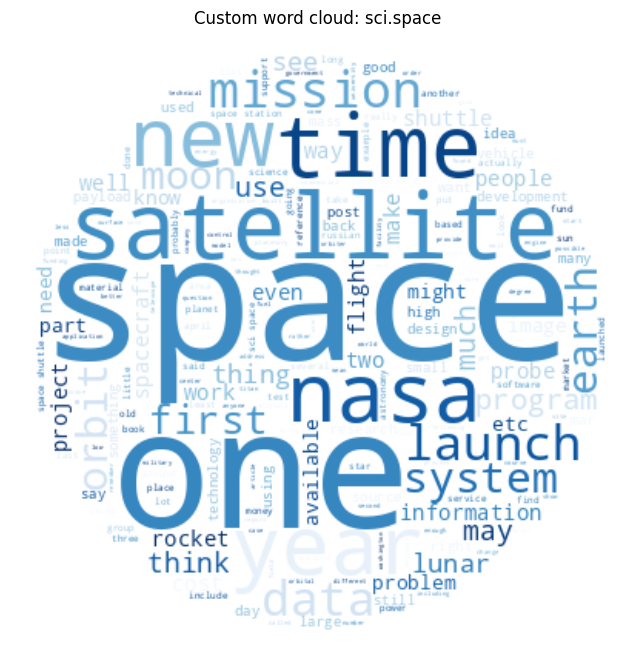

In [13]:
from PIL import Image

def circle_mask(size=400):
    y, x = np.ogrid[:size, :size]
    center, r = size // 2, size // 2 - 10
    mask = np.full((size, size), 255, dtype=np.uint8)   # 255 = masked out
    mask[(x - center) ** 2 + (y - center) ** 2 <= r ** 2] = 0   # 0 = draw here
    return mask

mask = circle_mask()
# To use your own image instead:  mask = np.array(Image.open("my_shape.png").convert("L"))

selected_category = "sci.space"  # YOUR CODE HERE: one of your categories
texts = df_filtered.loc[df_filtered["label_text"] == selected_category, "text_clean"]

# Combine texts into a single string and generate the WordCloud
text_combined = " ".join(texts)
wordcloud_masked = WordCloud(width=800, height=800, background_color="white", mask=mask, colormap="Blues").generate(text_combined)    # YOUR CODE HERE

plt.figure(figsize=(8, 8))
plt.imshow(wordcloud_masked.to_image(), interpolation="bilinear")
plt.title(f"Custom word cloud: {selected_category}")
plt.axis("off")
plt.show()

In [14]:
space_texts = df_filtered.loc[df_filtered["label_text"] == "sci.space", "text_clean"]
top_10_space = get_top_words(space_texts, n=10)
for rank, (word, freq) in enumerate(top_10_space, 1):
    print(f"{rank}. {word}: {freq}")

1. space: 986
2. would: 370
3. nasa: 328
4. launch: 314
5. one: 291
6. satellite: 287
7. year: 277
8. system: 266
9. time: 243
10. also: 236


---
# Part D – Bag of Words

In [15]:
sample_docs = ["I love machine learning", "Machine learning is great", "I love deep learning too"]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(sample_docs)

print("Vocabulary:", bow_vectorizer.get_feature_names_out())
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())
bow_df

Vocabulary: ['deep' 'great' 'is' 'learning' 'love' 'machine' 'too']


,deep,great,is,learning,love,machine,too
0,0,0,0,1,1,1,0
1,0,1,1,1,0,1,0
2,1,0,0,1,1,0,1


### Exercise D.1 – Bag of Words of your corpus

In [16]:
# Build the BoW matrix of df_filtered["text_clean"] with max_features=1000, min_df=5, max_df=0.95
bow_vectorizer_full = CountVectorizer(max_features=1000, min_df=5, max_df=0.95)  # YOUR CODE HERE
bow_matrix_full = bow_vectorizer_full.fit_transform(df_filtered["text_clean"])      # YOUR CODE HERE

print(f"BoW matrix shape: {bow_matrix_full.shape}")
print(f"Sparsity: {100 * (1 - bow_matrix_full.nnz / np.prod(bow_matrix_full.shape)):.1f}% of zeros")
print(f"First 20 words: {bow_vectorizer_full.get_feature_names_out()[:20]}")
assert bow_matrix_full.shape == (len(df_filtered), 1000), "Check the vectorizer parameters"

BoW matrix shape: (1792, 1000)
Sparsity: 96.3% of zeros
First 20 words: ['abc' 'able' 'absolute' 'accept' 'access' 'according' 'account' 'act'
 'action' 'activity' 'actually' 'adam' 'add' 'address' 'aerospace' 'age'
 'agency' 'ago' 'agree' 'ahl']


### Exercise D.2 – Document similarity

In [17]:
# 1. Compute the cosine similarity matrix between all documents (BoW vectors)
similarity_matrix = cosine_similarity(bow_matrix_full)

# 2. Find the most similar pair of distinct documents (ignore the diagonal)
# Create a copy of the similarity matrix and fill the diagonal with -1
sim_temp = similarity_matrix.copy()
np.fill_diagonal(sim_temp, -1)

# Find the flat index of the maximum value, then convert to 2D indices
flat_idx = np.argmax(sim_temp)
i, j = np.unravel_index(flat_idx, sim_temp.shape)

most_similar_idx = (i, j)
most_similar_score = sim_temp[i, j]

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Most similar documents: {most_similar_idx}, score = {most_similar_score:.3f}")
assert similarity_matrix.shape == (len(df_filtered), len(df_filtered)) and most_similar_idx[0] != most_similar_idx[1]

for k, idx in enumerate(most_similar_idx, 1):
    print(f"\nDocument {k} ({df_filtered.iloc[idx]['label_text']}):")
    print(df_filtered.iloc[idx]["text"][:300])

Similarity matrix shape: (1792, 1792)
Most similar documents: (np.int64(733), np.int64(767)), score = 1.000

Document 1 (sci.space):
Can someone please remind me who said a well known quotation? 

He was sitting atop a rocket awaiting liftoff and afterwards, in answer to
the question what he had been thinking about, said (approximately) "half a
million components, each has to work perfectly, each supplied by the lowest
bidder....

Document 2 (sci.space):
Can someone please remind me who said a well known quotation? 

He was sitting atop a rocket awaiting liftoff and afterwards, in answer to
the question what he had been thinking about, said (approximately) "half a
million components, each has to work perfectly, each supplied by the lowest
bidder....


### Question D.3 (written)

1. Are the two most similar documents from the same category?
2. Reading them, what makes them similar?
3. Is BoW cosine similarity meaningful here? Why?

<!-- ANSWER lab3.1-D3 -->
**Your answer:**BoW cosine similarity is partly meaningful: it detects documents that use the same words, so it works for finding same-topic documents. But it only counts word overlap, not meaning. It ignores word order, treats generic frequent words like important ones, and can’t tell that two different words mean the same thing.

*(write here)*
<!-- END ANSWER -->

---
# Part E – TF-IDF

In [18]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(sample_docs)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()).round(3)
tfidf_df

,deep,great,is,learning,love,machine,too
0,0.000,0.000,0.000,0.481,0.620,0.620,0.000
1,0.000,0.584,0.584,0.345,0.000,0.445,0.000
2,0.584,0.000,0.000,0.345,0.445,0.000,0.584


In [19]:
print("Scores of the word 'learning' (present in every document):")
print("  BoW:   ", bow_df["learning"].tolist())
print("  TF-IDF:", tfidf_df["learning"].tolist(), "-> lower weight for a word shared by all documents")

Scores of the word 'learning' (present in every document):
  BoW:    [1, 1, 1]
  TF-IDF: [0.481, 0.345, 0.345] -> lower weight for a word shared by all documents


### Exercise E.1 – TF-IDF of your corpus and top words per category

In [20]:
tfidf_vectorizer_full = TfidfVectorizer(max_features=1000, min_df=5, max_df=0.95)
tfidf_matrix_full = tfidf_vectorizer_full.fit_transform(df_filtered["text_clean"])
print(f"TF-IDF matrix shape: {tfidf_matrix_full.shape}")

def get_top_tfidf_words(category, n=10):
    """Words with the highest mean TF-IDF over the documents of a category."""
    # 1. Get indices of the documents of this category
    category_indices = df_filtered[df_filtered["label_text"] == category].index

    # 2. Extract their TF-IDF rows
    category_rows = tfidf_matrix_full[category_indices]

    # 3. Calculate mean score of each word over these rows
    mean_scores = np.asarray(category_rows.mean(axis=0)).flatten()

    # 4. Map back to vocabulary words and find the top n words with the highest mean
    feature_names = tfidf_vectorizer_full.get_feature_names_out()
    top_indices = np.argsort(mean_scores)[::-1][:n]

    return [(feature_names[i], mean_scores[i]) for i in top_indices]

for category in my_categories:
    print(f"\nTop TF-IDF words for '{category}':")
    print(get_top_tfidf_words(category, 10))
assert len(get_top_tfidf_words(my_categories[0], 10)) == 10

TF-IDF matrix shape: (1792, 1000)

Top TF-IDF words for 'sci.space':
[('space', np.float64(0.07269734977452784)), ('would', np.float64(0.0376509493363076)), ('nasa', np.float64(0.0282634107556452)), ('like', np.float64(0.02792191835079064)), ('one', np.float64(0.026983595074734083)), ('orbit', np.float64(0.02665291148042681)), ('launch', np.float64(0.026601903843696328)), ('get', np.float64(0.024117972619943844)), ('moon', np.float64(0.02311654307055727)), ('could', np.float64(0.021603767312956466))]

Top TF-IDF words for 'rec.sport.hockey':
[('game', np.float64(0.07493948643607504)), ('team', np.float64(0.061161899945756465)), ('player', np.float64(0.043395913792898325)), ('hockey', np.float64(0.04247135795178854)), ('play', np.float64(0.034892940216174256)), ('season', np.float64(0.03219219920069938)), ('year', np.float64(0.0308618695549543)), ('would', np.float64(0.02743535587218457)), ('nhl', np.float64(0.027263097633948758)), ('playoff', np.float64(0.027049179077093515))]

Top TF-

### Question E.2 (written)

Compare with the word counts of Part C:
1. Which words appear in the TF-IDF top 10 but not in the count top 15?
2. Which words appear in the count top 15 but not in the TF-IDF top 10?
3. Which representation captures the *topic* of each category better? Why?

<!-- ANSWER lab3.1-E2 -->
**Your answer:**

1. **Words in TF-IDF top 10 but not in count top 15:**
   - *sci.space*: `could`
   - *rec.sport.hockey*: `nhl`, `playoff`
   - *soc.religion.christian*: `bible`, `believe`

2. **Words in count top 15 but not in TF-IDF top 10:**
   - Highly frequent but less informative words such as `also`, `system`, `time`, and `get` dropped out of the top rankings because they are used across many documents in different categories.

3. **Better representation:**
   - **TF-IDF** captures the topics much better because it actively downweights terms that are common across the entire collection (high Document Frequency) and highlights words that are distinctively frequent within specific documents (like `nhl`, `playoff`, or `bible`). This acts as an automatic filter for domain-specific vocabulary.
<!-- END ANSWER -->

---
# Part F – N-grams and next-word prediction

In [21]:
from nltk import ngrams

tokens = "I love natural language processing and machine learning".split()
print("Bigrams: ", list(ngrams(tokens, 2)))
print("Trigrams:", list(ngrams(tokens, 3)))

# CountVectorizer can also build n-gram features
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_vectorizer.fit(["I love machine learning", "Machine learning is great"])
print("Bigram features:", bigram_vectorizer.get_feature_names_out())

Bigrams:  [('I', 'love'), ('love', 'natural'), ('natural', 'language'), ('language', 'processing'), ('processing', 'and'), ('and', 'machine'), ('machine', 'learning')]
Trigrams: [('I', 'love', 'natural'), ('love', 'natural', 'language'), ('natural', 'language', 'processing'), ('language', 'processing', 'and'), ('processing', 'and', 'machine'), ('and', 'machine', 'learning')]
Bigram features: ['is great' 'learning is' 'love machine' 'machine learning']


### Exercise F.1 – Most frequent bigrams per category

In [22]:
def top_bigrams(texts, n=15):
    """(bigram, count) list of the n most frequent bigrams in the texts."""
    # 1. CountVectorizer(ngram_range=(2, 2), min_df=3) fitted on the texts
    vectorizer = CountVectorizer(ngram_range=(2, 2), min_df=3)

    # Check if texts is empty or has no matching n-grams to avoid Fitting errors
    try:
        dtm = vectorizer.fit_transform(texts)
    except ValueError:
        return []

    # 2. sum the columns to count each bigram
    counts = np.asarray(dtm.sum(axis=0)).flatten()
    feature_names = vectorizer.get_feature_names_out()

    # Pair the feature names with their counts
    bigram_counts = list(zip(feature_names, counts))

    # 3. return the n most frequent (bigram, count)
    bigram_counts.sort(key=lambda x: x[1], reverse=True)
    return bigram_counts[:n]

for category in my_categories:
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    print(f"\nTop bigrams for '{category}':")
    for bigram, count in top_bigrams(texts, 15):
        print(f"  {bigram}: {count}")
assert len(top_bigrams(df_filtered["text_clean"], 5)) == 5


Top bigrams for 'sci.space':
  space station: 69
  space shuttle: 66
  sci space: 58
  anonymous ftp: 38
  commercial space: 32
  remote sensing: 32
  gamma ray: 28
  launch vehicle: 27
  national space: 26
  sci astro: 25
  air force: 24
  nasa ames: 24
  nasa gov: 24
  space technology: 23
  pub space: 21

Top bigrams for 'rec.sport.hockey':
  power play: 145
  play scorer: 63
  san jose: 62
  third period: 58
  new jersey: 56
  second period: 56
  los angeles: 55
  first period: 53
  hockey league: 52
  tampa bay: 50
  stanley cup: 49
  new york: 45
  brind amour: 42
  last year: 42
  maple leaf: 40

Top bigrams for 'soc.religion.christian':
  holy spirit: 62
  jesus christ: 45
  father son: 36
  would like: 36
  catholic church: 28
  absolute truth: 27
  answer question: 26
  new testament: 25
  non christian: 25
  would say: 22
  many people: 20
  second coming: 20
  word god: 20
  eternal life: 19
  jesus say: 18


### Exercise F.2 – A bigram next-word predictor

The probability of a word given the previous one is estimated by counting: P(w2 | w1) = count(w1, w2) / count(w1).

In [23]:
class BigramPredictor:
    def __init__(self):
        self.bigram_counts = {}   # {word1: Counter({word2: count, ...})}
        self.unigram_counts = Counter()

    def train(self, texts):
        """Count unigrams and bigrams over a list of texts (strings)."""
        for text in texts:
            words = text.split()
            if not words:
                continue
            # Update unigrams
            self.unigram_counts.update(words)
            # Update bigrams
            for w1, w2 in zip(words[:-1], words[1:]):
                if w1 not in self.bigram_counts:
                    self.bigram_counts[w1] = Counter()
                self.bigram_counts[w1][w2] += 1

    def predict_next(self, word, top_n=5):
        """Return the top_n (next_word, probability) pairs for a word."""
        if word not in self.bigram_counts or self.unigram_counts[word] == 0:
            return []

        total_occurrences = self.unigram_counts[word]
        candidates = self.bigram_counts[word].most_common(top_n)

        # Compute conditional probabilities
        return [(next_word, count / total_occurrences) for next_word, count in candidates]

# Sanity check on a tiny corpus
toy = BigramPredictor()
toy.train(["the cat sat on the mat", "the cat ate the fish"])
print(toy.predict_next("the"))
assert toy.predict_next("the")[0] == ("cat", 0.5), "P(cat | the) should be 2/4"
assert toy.predict_next("cat") == [("sat", 0.5), ("ate", 0.5)] or toy.predict_next("cat") == [("ate", 0.5), ("sat", 0.5)]

predictor = BigramPredictor()
predictor.train(df_filtered["text_clean"])

[('cat', 0.5), ('mat', 0.25), ('fish', 0.25)]


In [24]:
# Choose 5 words related to YOUR categories and look at the predictions
test_words = ["space", "orbit", "game", "team", "god"]

for word in test_words:
    print(f"\n'{word}' ->")
    for next_word, prob in predictor.predict_next(word.lower(), top_n=5):
        print(f"  {next_word}: {prob:.3f}")


'space' ->
  station: 0.069
  shuttle: 0.066
  technology: 0.023
  program: 0.020
  news: 0.019

'orbit' ->
  moon: 0.022
  earth: 0.022
  trajectory: 0.017
  around: 0.013
  ssto: 0.013

'game' ->
  played: 0.033
  point: 0.018
  pick: 0.017
  season: 0.016
  misconduct: 0.014

'team' ->
  would: 0.022
  play: 0.016
  top: 0.015
  record: 0.013
  get: 0.013

'god' ->
  love: 0.012
  god: 0.011
  father: 0.010
  revelation: 0.010
  want: 0.010


### Question F.3 (written)

1. Give 2 sensible predictions and 2 poor ones.
2. What are the limits of a bigram model?
3. How could the predictor be improved? (3 ideas)

<!-- ANSWER lab3.1-F3 -->
**Your answer:**

1. **Sensible vs. Poor Predictions:**
   - **Sensible:** `'space' -> station` ($P=0.069$) and `'orbit' -> moon` ($P=0.022$) because they represent highly logical and frequently occurring collocations in astronomy and aerospace.
   - **Poor:** `'team' -> would` ($P=0.022$) because `would` is a generic helper verb that doesn't form a meaningful multi-word phrase, and `'god' -> god` ($P=0.011$) which is redundant.

2. **Limits of a Bigram Model:**
   - **Lack of context:** It only looks at the immediately preceding word. It cannot maintain grammatical agreement or semantic consistency over longer clauses.
   - **Sparsity:** Unseen word sequences immediately receive a probability of 0.

3. **Improvement Ideas:**
   - **Increase N-gram size:** Use trigram ($N=3$) or quadgram ($N=4$) models to keep broader syntactic history.
   - **Implement Smoothing:** Use Laplace (add-one), Backoff, or Interpolation (like Kneser-Ney) to assign realistic non-zero probabilities to unseen pairs.
   - **Apply Neural Networks / Transformers:** Use word embeddings (such as Word2Vec or LSTMs/Transformers) to capture semantic similarities so that synonyms can share context.

---
# Part G – Document similarity heatmap

TF-IDF cosine similarity between 30 documents (10 per category).

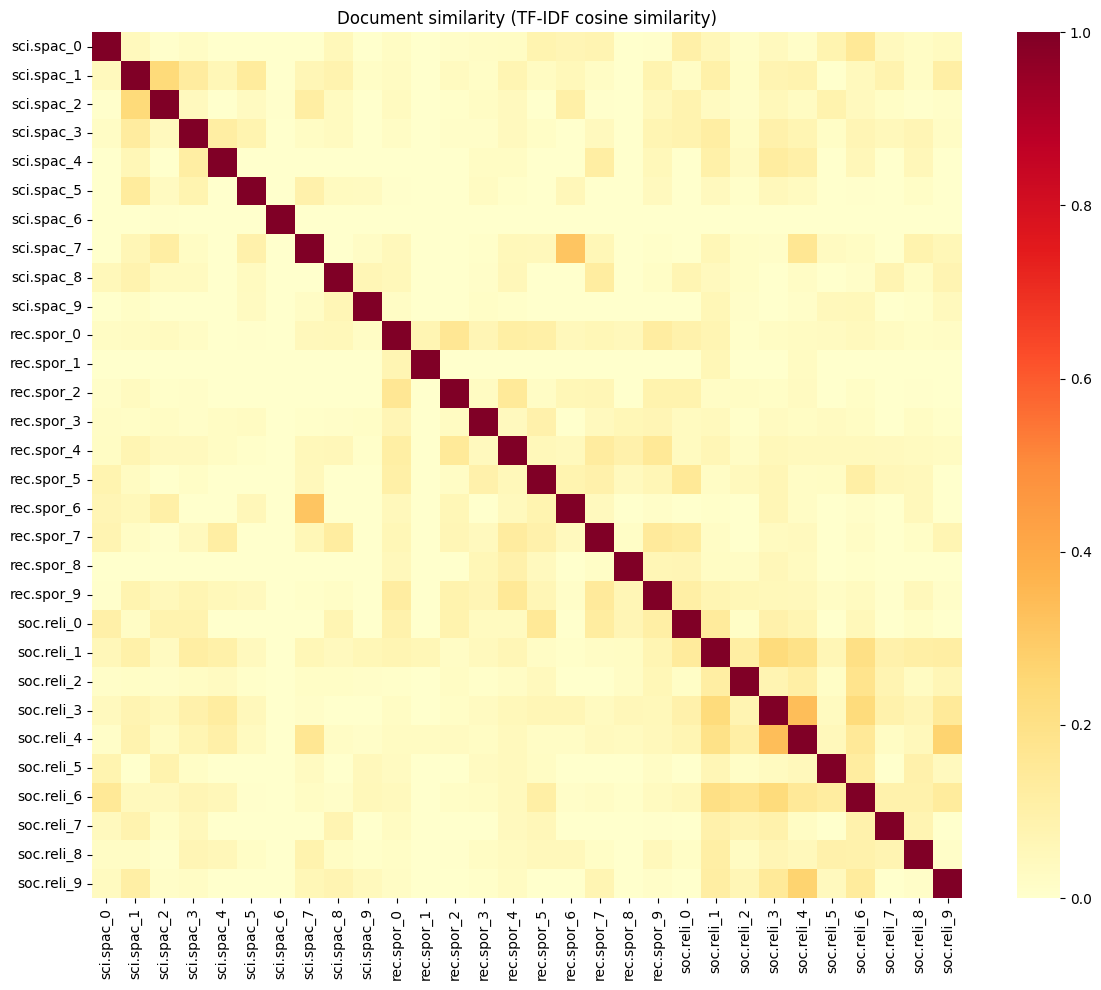

In [25]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
tfidf_sampled = TfidfVectorizer(max_features=500).fit_transform(df_sampled["text_clean"])
similarity_sampled = cosine_similarity(tfidf_sampled)

labels = [f"{cat[:8]}_{i % 10}" for i, cat in enumerate(df_sampled["label_text"])]
plt.figure(figsize=(12, 10))
sns.heatmap(similarity_sampled, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (TF-IDF cosine similarity)")
plt.tight_layout()
plt.show()

### Question G.1 (written)

1. Do documents of the same category form brighter blocks along the diagonal?
2. Which pair of categories is the most similar? The least similar?
3. Any surprising similarity between documents of different categories? What could explain it?

<!-- ANSWER lab3.1-G1 -->
**Your answer:**
[Yes / mostly yes: documents of the same category form brighter blocks along the diagonal, because they share topic vocabulary. The most similar pair of categories is [look at the off-diagonal blocks: the brightest one]. The least similar pair is [the darkest block]. (I’d expect hockey and christian to be the most different, but check your heatmap.) explanation is that both documents are short or contain mostly generic words, or one quotes text from the other topic, so they share common words even though the topics differ.
*(write here)*
<!-- END ANSWER -->

---
## Summary

- Word counts and word clouds give a first picture of a corpus, after cleaning.
- Bag of Words counts words; TF-IDF down-weights words shared by many documents.
- N-grams capture short sequences; a bigram model is the simplest language model.
- Cosine similarity on these vectors measures lexical overlap, not meaning. Lab 3.2 moves to embeddings.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.